# IS 362 – Week 8 Assignment 6: Auto MPG Data Analysis

**Nathan Fernandez**

## Introduction

This assignment explores the Auto MPG dataset from the University of California, Irvine (UCI) Machine Learning Repository using Python, pandas, Matplotlib, and Seaborn.

The dataset contains information about automobiles, including fuel efficiency (miles per gallon), cylinders, horsepower, weight, and country of origin.

The goal is to load the dataset directly from the online repository, perform data cleaning and transformation operations, and use exploratory data analysis to examine the distribution of variables and relationships between them.

The analysis will include a bar chart showing the distribution of cylinders, a scatterplot examining the relationship between horsepower and weight, and an additional visualization to investigate an interesting question about the dataset.

All data preparation and analysis will be performed within this notebook to ensure the results are reproducible.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"

auto_mpg = pd.read_csv(url, sep=r"\s+", header=None, quotechar='"')

auto_mpg.head()

,0,1,2,3,4,5,6,7,8
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [3]:
auto_mpg.columns = [
    "mpg",
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model_year",
    "origin",
    "car_name"
]

auto_mpg.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [4]:
auto_mpg.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    str    
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


In [5]:
auto_mpg["horsepower"] = pd.to_numeric(
    auto_mpg["horsepower"].replace("?", pd.NA),
    errors="coerce"
)

auto_mpg["horsepower"].isna().sum()

np.int64(6)

In [6]:
auto_mpg["origin"] = auto_mpg["origin"].replace({
    1: "USA",
    2: "Asia",
    3: "Europe"
})

auto_mpg["origin"].value_counts()

origin
USA       249
Europe     79
Asia       70
Name: count, dtype: int64

## Data Preparation and Cleaning

The Auto MPG dataset was loaded directly from the UCI Machine Learning Repository using `pd.read_csv()`. This approach allows the notebook to retrieve the original data without requiring a locally downloaded file.

The dataset contains 398 automobile records and nine columns. I assigned descriptive column names based on the attribute information provided in the dataset documentation.

After inspecting the DataFrame with `.info()`, I identified that the `horsepower` column was stored as text because some values were represented by question marks (`?`). I replaced these question marks with missing values and converted the column to a numeric data type using `pd.to_numeric()`. This revealed six missing horsepower values.

I also converted the numerical values in the `origin` column into descriptive geographic labels, following the assignment instructions: 1 = USA, 2 = Asia, and 3 = Europe.

After this transformation, the dataset contained 249 automobiles from the USA, 79 from Europe, and 70 from Asia.

These cleaning and transformation operations were performed entirely within the notebook to ensure the analysis is reproducible.

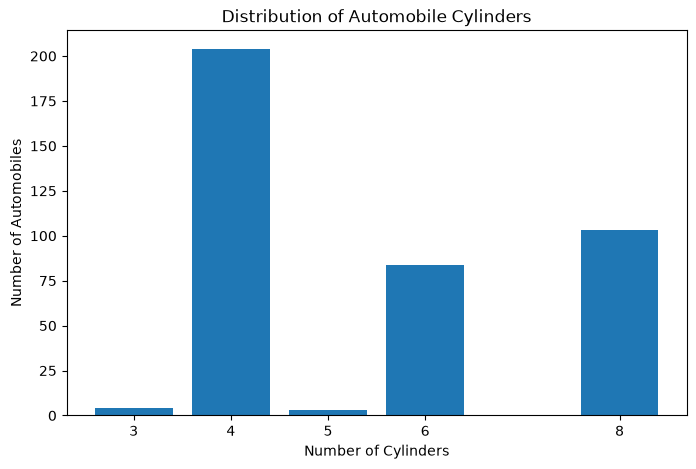

In [7]:
cylinder_counts = auto_mpg["cylinders"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(cylinder_counts.index, cylinder_counts.values)

plt.title("Distribution of Automobile Cylinders")
plt.xlabel("Number of Cylinders")
plt.ylabel("Number of Automobiles")
plt.xticks(cylinder_counts.index)

plt.show()

## Distribution of Automobile Cylinders

I created a bar chart using Matplotlib to examine the distribution of cylinder counts in the Auto MPG dataset. I used `.value_counts()` to count the number of automobiles with each cylinder configuration and `.sort_index()` to display them in numerical order.

The chart shows that 4-cylinder automobiles are the most common, followed by 8-cylinder and 6-cylinder automobiles. Vehicles with 3 or 5 cylinders are much less common.

This suggests that the dataset is primarily composed of automobiles with 4, 6, or 8 cylinders, with 4-cylinder vehicles representing the largest group.

The distribution also demonstrates that cylinder configurations are not equally represented in the dataset, which is important to consider when comparing vehicle characteristics.

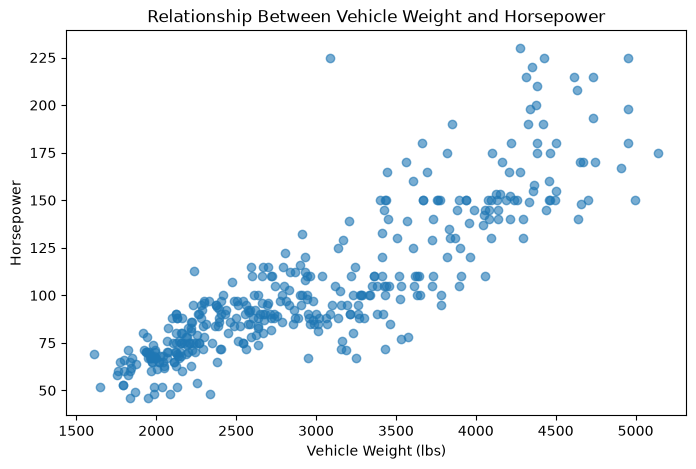

In [8]:
plt.figure(figsize=(8, 5))

plt.scatter(auto_mpg["weight"], auto_mpg["horsepower"], alpha=0.6)

plt.title("Relationship Between Vehicle Weight and Horsepower")
plt.xlabel("Vehicle Weight (lbs)")
plt.ylabel("Horsepower")

plt.show()

## Relationship Between Vehicle Weight and Horsepower

I created a scatterplot using Matplotlib to examine the relationship between vehicle weight and horsepower in the Auto MPG dataset. Each point represents an automobile, with vehicle weight displayed on the horizontal axis and horsepower on the vertical axis.

The scatterplot shows a positive relationship between vehicle weight and horsepower. Lighter automobiles generally have lower horsepower, while heavier automobiles tend to have higher horsepower.

Vehicles weighing approximately 1,500 to 2,500 pounds typically have lower horsepower values, while vehicles weighing 4,000 pounds or more generally have higher horsepower values.

Although there is some variation among individual automobiles, the overall pattern suggests that heavier vehicles tend to have more powerful engines.

The six automobiles with missing horsepower values were excluded from the scatterplot automatically because their horsepower values were converted to missing values during data cleaning.

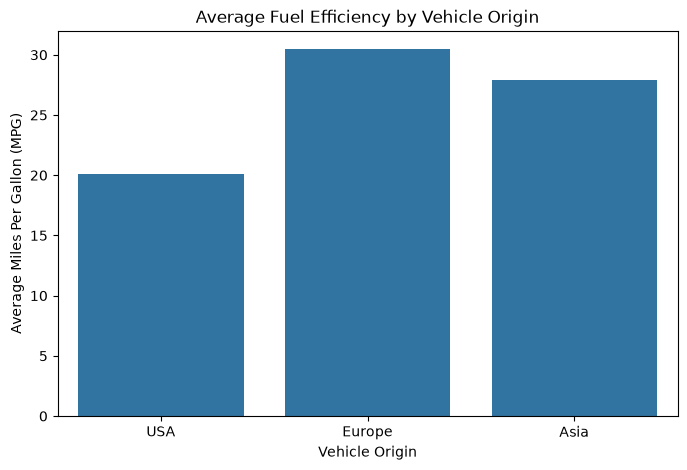

In [9]:
plt.figure(figsize=(8, 5))

sns.barplot(data=auto_mpg, x="origin", y="mpg", errorbar=None)

plt.title("Average Fuel Efficiency by Vehicle Origin")
plt.xlabel("Vehicle Origin")
plt.ylabel("Average Miles Per Gallon (MPG)")

plt.show()

## Exploratory Analysis: Fuel Efficiency by Vehicle Origin

### Research Question

Do automobiles from different geographic regions have different average fuel efficiency (MPG)?

### Analysis

To answer this question, I created a bar chart using Seaborn to compare the average miles per gallon (MPG) of automobiles from the USA, Europe, and Asia.

Based on the chart, European automobiles have the highest average fuel efficiency at roughly 30 MPG, followed by Asian automobiles at roughly 28 MPG. American automobiles have the lowest average at roughly 20 MPG.

This suggests a difference of roughly 10 MPG between European and American automobiles in the dataset.

### Findings

Based on this dataset, European and Asian automobiles generally have higher average fuel efficiency than American automobiles.

However, these results describe the vehicles represented in the Auto MPG dataset and do not necessarily reflect all automobiles manufactured in these regions. Other factors, such as vehicle weight, engine size, and model year, may also influence fuel efficiency.

This analysis demonstrates how Seaborn visualizations can help identify patterns and differences between groups of automobiles.

## Overall Conclusion

This assignment explored the Auto MPG dataset from the UCI Machine Learning Repository using Python, pandas, Matplotlib, and Seaborn. The dataset was loaded directly from the internet, and all data cleaning and transformation operations were performed within the Jupyter Notebook to ensure reproducibility.

During data preparation, I identified six missing horsepower values and converted the horsepower column into a numeric data type. I also replaced the numerical origin codes with descriptive geographic labels.

The first visualization showed that 4-cylinder automobiles were the most common in the dataset, followed by 8-cylinder and 6-cylinder automobiles. The second visualization revealed a positive relationship between vehicle weight and horsepower, suggesting that heavier vehicles generally have more powerful engines.

For the additional exploratory analysis, I compared average fuel efficiency across vehicle origins. The Seaborn bar chart showed that European automobiles had the highest average MPG, followed by Asian automobiles, while American automobiles had the lowest average MPG.

In the end, these findings demonstrate how data cleaning and visualization can help identify patterns and relationships within a dataset. They also highlight the importance of considering multiple vehicle characteristics when exploring differences in automobile performance and fuel efficiency.